# SR-UKF for a mass-spring-damper system

A self-contained, executed Python tutorial following **Algorithm 3.1** in the attached paper by van der Merwe and Wan.

You will construct the MSD model, derive the sigma-point moments, follow each prediction/update equation, inspect one numerical iteration, reconstruct position and unmeasured velocity, and validate the complete result against an independent linear Kalman filter. The companion MATLAB script uses the same benchmark and equation-linked comments.

The source notation is retained: $\mathbf R^v$ and $\mathbf R^n$ denote noise covariances, $W_i^{(m)}$ and $W_i^{(c)}$ denote distinct weights, and $\mathbf P=\mathbf S\mathbf S^T$ denotes a column square root.


## 1. The mass-spring-damper model and the paper's symbols

Write the mechanical equation using $p$ for position and $d$ for velocity, so the paper's $v_k$ can continue to mean **process noise**:

$$m\ddot p+b\dot p+k_rp=u,\qquad
\mathbf{x}=\begin{bmatrix}p\\d\end{bmatrix},\qquad
\dot{\mathbf{x}}=A\mathbf{x}+Bu,$$
$$A=\begin{bmatrix}0&1\\-k_r/m&-b/m\end{bmatrix},\quad
B=\begin{bmatrix}0\\1/m\end{bmatrix}.$$

Both tutorials and both MATLAB scripts use $m=1$ kg, $b=0.5$ N s/m, $k_r=1.9$ N/m, $T_s=0.01$ s, $u_k=0.1\sin(kT_s)$ N, and a 10 s run.

The example uses **forward Euler**, not exact zero-order hold. Applying $\mathbf{x}_{k+1}\approx\mathbf{x}_k+T_s\dot{\mathbf{x}}_k$ gives
$$A_d=I+T_sA,\qquad B_d=T_sB,\qquad
\mathbf{F}[\mathbf{x}_k,u_k]=A_d\mathbf{x}_k+B_du_k.$$
The paper's Eqs. (1)-(2) become
$$\mathbf{x}_{k+1}=\mathbf{F}[\mathbf{x}_k,u_k]+\mathbf{v}_k,\qquad
y_k=\mathbf{H}[\mathbf{x}_k]+n_k,\qquad \mathbf{H}[\mathbf{x}]=[1\;0]\mathbf{x}.$$

The deterministic function $\mathbf{F}$ does not draw random numbers. Noise enters the simulated plant separately, and its covariance enters the filter through $\mathbf{R}^v$ and $\mathbf{R}^n$.

| Paper | Code | Meaning and shape |
|---|---|---|
| $L$ | `L` | State dimension, 2 |
| $\hat{\mathbf{x}}_k$ | `x_hat[:, k]` | Posterior mean, `(2,)` |
| $\hat{\mathbf{x}}_k^-$ | `x_hat_minus` | Predicted mean, `(2,)` |
| $\mathcal{X}_{k-1}$ | `X` | Prior sigma points, `(2, 5)` |
| $\mathcal{X}_{k\mid k-1}$ | `X_minus` | Propagated sigma points, `(2, 5)` |
| $\mathcal{Y}_{k\mid k-1}$ | `Y_minus` | Observation sigma points, `(1, 5)` |
| $\hat y_k^-$ | `y_hat_minus` | Predicted position, `(1,)` |
| $\mathbf{P}_{\tilde y_k\tilde y_k}$ | `P_yy` | Innovation covariance, `(1, 1)` |
| $\mathbf{P}_{x_ky_k}$ | `P_xy` | Cross covariance, `(2, 1)` |
| $\mathbf{K}_k$ | `K` | Kalman gain, `(2, 1)` |
| $\mathbf{R}^v$ | `Rv` | Discrete process-noise covariance, `(2, 2)` |
| $\mathbf{R}^n$ | `Rn` | Position-noise covariance, `(1, 1)` |

Python column `k` represents paper time $k$; MATLAB column `k+1` represents the same time. The central sigma point is Python column 0 and MATLAB column 1. The physical spring stiffness is `kr`, leaving `k` for the filter time index.


In [1]:
import numpy as np  # Numerical arrays for the paper's vectors and matrices.
import matplotlib.pyplot as plt  # Tutorial figures; not part of the filter recursion.
from scipy.linalg import solve_triangular  # Section 3: factor-based linear solves.
np.set_printoptions(precision=8, suppress=True)  # Tutorial output formatting.


## 2. Noise timing and initialization

The demonstration uses acceleration noise $a_k\sim\mathcal{N}(0,w^2)$ with $w=10^{-4}$ m/s$^2$. Euler integration gives
$$\mathbf v_k=\begin{bmatrix}0\\T_sa_k\end{bmatrix},\qquad
\mathbf R^v=\begin{bmatrix}0&0\\0&T_s^2w^2\end{bmatrix},\qquad
\sqrt{\mathbf R^v}=\begin{bmatrix}0&0\\0&T_sw\end{bmatrix}.$$
With measurement standard deviation $v=10^{-3}$ m, $\mathbf R^n=[v^2]=[10^{-6}]$ m$^2$. The lowercase code names `w` and `v` are simulation standard deviations, not the paper's noise vectors. Both filters use fixed noise covariances.

Why this timing? Algorithms 2.1 and 3.1 propagate **one** sigma-point set and observe that set; $\mathbf R^v$ is added to the state covariance separately. In this example $H\mathbf R^v=0$: the fresh acceleration disturbance changes this step's velocity, while the observation measures this step's position. Therefore that disturbance contributes neither to $\mathbf P_{x_ky_k}$ nor to $\mathbf P_{\tilde y_k\tilde y_k}$ at this step, and the printed single-set structure agrees with the linear Kalman filter. Its effect on later positions is already represented in the next posterior sigma set.

For a different noise model with $H\mathbf R^v\ne0$, or an exact-ZOH force-disturbance map with a position component, that equivalence does not follow. A general additive-noise implementation would need to carry the fresh process-noise contribution into the observation moments (for example, by augmentation or a new sigma set). This tutorial deliberately retains the paper's one-set algorithms.

Use $\hat{\mathbf x}_0=[0.1\;0.2]^T$ and $\mathbf P_0=\mathrm{diag}(0.5,0.18)$. The first update assimilates $y_1$; $y_0$ is stored for plotting. The actual initial state is $[1\;0.1]^T$; it is fixed for this demonstration, not sampled from the prior. Consequently the uncertainty envelopes are conditional Gaussian-model diagnostics, not a Monte Carlo coverage claim.


In [2]:
Ts = 1e-2  # MSD forward-Euler sampling period.
N = int(round(10.0 / Ts)) + 1  # Demo: number of samples including time zero.
t = Ts * np.arange(N)  # Demo: time vector, with paper time index k.
m, b, kr = 1.0, 0.5, 1.9  # MSD physical parameters; k remains the time index.
u = 0.1 * np.sin(t)  # Paper Eq. (1): known input sequence u_k.
L = 2  # Section 2: dimension of x_k = [position, velocity].
A = np.array([[0.0, 1.0], [-kr / m, -b / m]])  # MSD continuous state matrix.
B = np.array([[0.0], [1.0 / m]])  # MSD continuous force input matrix.
Ad = np.eye(L) + Ts * A  # Paper F in Eqs. (1), (7), (18): Euler state map.
Bd = Ts * B  # Paper F: discrete force input map.
H = np.array([[1.0, 0.0]])  # Paper H in Eq. (2): measure position only.
w, v = 1e-4, 1e-3  # Demo: acceleration-noise and position-noise standard deviations.
sqrt_Rv = np.diag([0.0, Ts * w])  # Column factor of R^v; a PSD root needs no Cholesky call.
Rv = sqrt_Rv @ sqrt_Rv.T  # Paper R^v: discrete state-noise covariance.
Rn = np.array([[v**2]])  # Paper R^n: measurement-noise covariance.
sqrt_Rn = np.array([[v]])  # Paper sqrt(R^n): positive scalar factor.
x0 = np.array([1.0, 0.1])  # Demo: actual initial position and velocity.
x_hat0 = np.array([0.1, 0.2])  # Paper initialization, Eqs. (5)/(16): initial mean.
P0 = np.diag([0.5, 0.18])  # Paper initialization: initial error covariance.

def F(X, u_previous):  # Paper F: deterministic map applied to columns of sigma states.
    return Ad @ X + Bd * u_previous  # Eqs. (7)/(18): F[X_{k-1}, u_{k-1}].

rng = np.random.default_rng(0)  # Demo: identical Python data in both tutorials.
x = np.zeros((L, N))  # Demo: simulated state trajectory.
y = np.zeros((1, N))  # Paper y_k: measured position trajectory.
x[:, 0] = x0  # Demo: initialize the true state x_0.
y[:, 0] = H @ x0 + sqrt_Rn @ rng.standard_normal(1)  # Eq. (2): initial measurement for plots.
for k in range(1, N):  # Demo: simulate the discrete-time plant.
    x[:, k] = F(x[:, k-1:k], u[k-1]).ravel() + sqrt_Rv @ rng.standard_normal(L)  # Eq. (1): F + v.
    y[:, k] = H @ x[:, k] + sqrt_Rn @ rng.standard_normal(1)  # Eq. (2): H[x_k] + n_k.
print('Ad =\n', Ad)  # Tutorial: inspect the model used by F.
print('Bd =\n', Bd)  # Tutorial: inspect the input map.
print('R^v =\n', Rv, '\nR^n =', Rn)  # Tutorial: distinguish covariances from standard deviations.


Ad =
 [[ 1.     0.01 ]
 [-0.019  0.995]]
Bd =
 [[0.  ]
 [0.01]]
R^v =
 [[0. 0.]
 [0. 0.]] 
R^n = [[0.000001]]


## 3. Sigma points and weights: the paper's notation

Use exactly the Section 2 definitions, with no additional $\kappa$ parameter:
$$\lambda=L(\alpha^2-1),\qquad \eta=\sqrt{L+\lambda},$$
$$W_0^{(m)}=\frac{\lambda}{L+\lambda},\qquad
W_0^{(c)}=\frac{\lambda}{L+\lambda}+1-\alpha^2+\beta,$$
$$W_i^{(m)}=W_i^{(c)}=\frac{1}{2(L+\lambda)},\quad i=1,\ldots,2L.$$
Here $L=2$, $\alpha=0.99$, $\beta=2$, giving five sigma points. For a column factor $\mathbf P=\mathbf S\mathbf S^T$,
$$\mathcal X=[\hat{\mathbf x}\quad\hat{\mathbf x}+\eta\mathbf S\quad\hat{\mathbf x}-\eta\mathbf S].$$
The additions operate column by column, as the paper defines. The weighted **mean** uses $W^{(m)}$; every covariance and cross covariance uses $W^{(c)}$. Only the mean weights must sum to one.


In [3]:
def weights(L, alpha=0.99, beta=2.0):  # Section 2: scaled unscented weights.
    lam = L * (alpha**2 - 1.0)  # Paper lambda; 'lambda' is a reserved Python word.
    eta = np.sqrt(L + lam)  # Paper eta = sqrt(L + lambda).
    Wm = np.full(2 * L + 1, 1.0 / (2.0 * (L + lam)))  # Paper noncentral W_i^(m).
    Wm[0] = lam / (L + lam)  # Paper central W_0^(m).
    Wc = Wm.copy()  # Paper noncentral W_i^(c) = W_i^(m).
    Wc[0] += 1.0 - alpha**2 + beta  # Paper central W_0^(c).
    return eta, Wm, Wc  # Expose the paper's scaling and weight vectors.

def sigma_points(x_hat_previous, S_previous, eta):  # Eqs. (6)/(17): column-oriented sigma construction.
    L = x_hat_previous.size  # Section 2: state dimension for this mean.
    offsets = np.column_stack((np.zeros(L), S_previous, -S_previous))  # Central, positive, negative columns.
    return x_hat_previous[:, None] + eta * offsets  # Eqs. (6)/(17): add the mean to each column.

eta, Wm, Wc = weights(L)  # Common settings for the UKF and SR-UKF.
print('eta =', eta, '\nW^(m) =', Wm, '\nW^(c) =', Wc)  # Tutorial: inspect all five weights.
assert np.isclose(Wm.sum(), 1.0)  # Mean weights must preserve an affine constant.


eta = 1.4000714267493641 
W^(m) = [-0.02030405  0.25507601  0.25507601  0.25507601  0.25507601] 
W^(c) = [1.99959595 0.25507601 0.25507601 0.25507601 0.25507601]


## 4. Algorithm 3.1: carry factors rather than full covariances

Throughout this notebook,
$$\mathbf P_k=\mathbf S_k\mathbf S_k^T,\qquad
\mathbf P_{\tilde y_k\tilde y_k}=\mathbf S_{\tilde y_k}\mathbf S_{\tilde y_k}^T,$$
and the stored factors are **lower triangular with positive diagonals**. This is the column-factor convention stated in Section 3 of the paper.

Initialize $\mathbf S_0=\mathrm{chol}(\mathbf P_0)$ once, Eq. (16). Form sigma points from the available previous posterior $\mathbf S_{k-1}$, Eq. (17), and propagate through $\mathbf F$, Eq. (18). Compute the same weighted state mean, Eq. (19).

Let $\delta\mathbf x_i=\mathcal X_{i,k\mid k-1}-\hat{\mathbf x}_k^-$. Construct
$$C_x=[\sqrt{W_1^{(c)}}\delta\mathbf x_1\ \cdots\ \sqrt{W_1^{(c)}}\delta\mathbf x_{2L}\ \sqrt{\mathbf R^v}].$$
All noncentral weights equal $W_1^{(c)}$. Factor $C_x^T=QR$ and set $\mathbf S_k^-=R^T$, Eq. (20), so $\mathbf S_k^-(\mathbf S_k^-)^T=C_xC_x^T$. Row sign normalization of $R$ leaves $R^TR$ unchanged and gives positive diagonals.

The central contribution is handled separately:
$$\mathbf S_k^-\leftarrow\operatorname{cholupdate}\{\mathbf S_k^-,\delta\mathbf x_0,W_0^{(c)}\}.\tag{21}$$
This notation means a signed rank-one operation: add $W_0^{(c)}\delta\mathbf x_0\delta\mathbf x_0^T$. Scale the update vector by $\sqrt{|W_0^{(c)}|}$ and use its sign to select an update or downdate. It works for positive or negative central weights.

Observe the time-updated sigma states at measurement time $k$, $\mathcal Y_{k\mid k-1}=\mathbf H[\mathcal X_{k\mid k-1}]$, and calculate $\hat{\mathbf y}_k^-$, Eqs. (22)-(23). Apply the same QR and signed central update to
$$C_y=[\sqrt{W_1^{(c)}}\delta\mathbf y_1\ \cdots\ \sqrt{W_1^{(c)}}\delta\mathbf y_{2L}\ \sqrt{\mathbf R^n}]$$
to obtain $\mathbf S_{\tilde y_k}$, Eqs. (24)-(25). Cross covariance still uses the weighted paired deviations, Eq. (26).

Two triangular solves implement
$$\mathbf K_k=(\mathbf P_{x_ky_k}/\mathbf S_{\tilde y_k}^T)/\mathbf S_{\tilde y_k}.\tag{27}$$
Update the state mean and form
$$\hat{\mathbf x}_k=\hat{\mathbf x}_k^-+\mathbf K_k(\mathbf y_k-\hat{\mathbf y}_k^-),\qquad
U=\mathbf K_k\mathbf S_{\tilde y_k}.\tag{28}$$
Finally, downdate the predicted factor once for each column of $U$, Eq. (29). Since $UU^T=\mathbf K_k\mathbf P_{\tilde y_k\tilde y_k}\mathbf K_k^T$, this is the factor representation of Eq. (14).

**Reading the displayed formulas with this convention.** Eq. (17) uses the previous posterior factor available before prediction. Eq. (22) uses the time-updated states being observed, consistently with Algorithm 2.1 and the paired deviations in Eq. (26). MATLAB `cholupdate` operates on an upper factor, so the transposes shown in Eq. (29) are implemented as `cholupdate(S_minus.T, ...).T`; the Python helper below accepts and returns lower factors directly. These conventions make every covariance product and time index explicit.


## 5. The two square-root operations in Python

`qr_column_factor(C)` returns a lower factor of $CC^T$ without forming $CC^T$.

`signed_cholupdate(S, column, weight)` returns a factor of
$$SS^T+\mathrm{weight}\;\mathrm{column}\;\mathrm{column}^T$$
using a rank-one update/downdate. At pivot $j$, with $a=S_{jj}$, scaled vector $z$, and sign $\epsilon\in\{-1,+1\}$, use
$$r=\sqrt{a^2+\epsilon z_j^2},\quad c=r/a,\quad s=z_j/a,$$
$$S_{j+1:,j}\leftarrow\frac{S_{j+1:,j}+\epsilon s z_{j+1:}}{c},\qquad
z_{j+1:}\leftarrow c z_{j+1:}-sS_{j+1:,j}.$$
The last formula uses the **updated** factor column. This performs $O(L^2)$ work for one column, as the paper's Section 3 describes. No full covariance is reconstructed inside this helper.

A downdate must leave the covariance positive definite for these positive-diagonal Cholesky routines. The helper raises an error if a pivot would be nonpositive; it does not insert jitter or change the covariance silently. Rectangular or singular noise roots are allowed in the QR input; the resulting state and innovation covariances must still admit the required factors.


In [4]:
def qr_column_factor(C):  # Section 3 / Eqs. (20), (24): factor of C @ C.T.
    _, R_upper = np.linalg.qr(C.T, mode='reduced')  # QR of the transposed column matrix.
    signs = np.where(np.diag(R_upper) < 0.0, -1.0, 1.0)  # Choose positive factor diagonals.
    R_upper = signs[:, None] * R_upper  # Row sign changes preserve R_upper.T @ R_upper.
    return R_upper.T  # Return lower S, satisfying S @ S.T = C @ C.T.

def signed_cholupdate(S, column, weight):  # Eqs. (21), (25), (29): lower-factor signed rank-one operation.
    S = np.array(S, dtype=float, copy=True)  # Preserve the supplied factor; return an updated copy.
    if weight == 0.0:  # Zero contribution needs no factor change.
        return S  # Return the unchanged lower factor.
    z = np.sqrt(abs(weight)) * np.array(column, dtype=float, copy=True)  # Weight the rank-one vector.
    sign = 1.0 if weight > 0.0 else -1.0  # Select covariance update or downdate.
    for j in range(S.shape[0]):  # Section 3: eliminate the weighted vector pivot by pivot.
        a = S[j, j]  # Current positive Cholesky pivot.
        if a <= 0.0:  # Factor convention requires positive input pivots.
            raise np.linalg.LinAlgError('Input factor must have positive diagonal entries.')  # Reject an invalid factor.
        r_squared = a * a + sign * z[j] * z[j]  # Signed rank-one contribution at this pivot.
        if r_squared <= 0.0 or not np.isfinite(r_squared):  # A valid Cholesky downdate must remain positive definite.
            raise np.linalg.LinAlgError('Signed Cholesky update is not positive definite.')  # Do not alter the covariance model.
        r = np.sqrt(r_squared)  # Updated factor pivot.
        c, s = r / a, z[j] / a  # Rank-one update/downdate coefficients.
        S[j, j] = r  # Store the new positive diagonal.
        S[j+1:, j] = (S[j+1:, j] + sign * s * z[j+1:]) / c  # Update the lower factor column.
        z[j+1:] = c * z[j+1:] - s * S[j+1:, j]  # Update the residual with the new column.
    return S  # Return the lower factor of the signed covariance change.


In [5]:
def srukf_step(x_hat_previous, S_previous, y_k, u_previous, eta, Wm, Wc):  # Algorithm 3.1: one step.
    X = sigma_points(x_hat_previous, S_previous, eta)  # Eq. (17): sigma points from the previous posterior factor.
    X_minus = F(X, u_previous)  # Eq. (18): deterministic propagation.
    x_hat_minus = X_minus @ Wm  # Eq. (19): predicted state mean.
    dX = X_minus - x_hat_minus[:, None]  # Eqs. (20)-(21): propagated state deviations.
    Cx = np.column_stack((np.sqrt(Wc[1]) * dX[:, 1:], sqrt_Rv))  # Eq. (20): noncentral columns and process-noise root.
    S_minus = qr_column_factor(Cx)  # Eq. (20): predicted factor without the central contribution.
    S_minus = signed_cholupdate(S_minus, dX[:, 0], Wc[0])  # Eq. (21): signed central contribution.
    Y_minus = H @ X_minus  # Eq. (22): observe the propagated sigma states.
    y_hat_minus = Y_minus @ Wm  # Eq. (23): predicted observation mean.
    dY = Y_minus - y_hat_minus[:, None]  # Eqs. (24)-(25): observation deviations.
    Cy = np.column_stack((np.sqrt(Wc[1]) * dY[:, 1:], sqrt_Rn))  # Eq. (24): noncentral columns and observation-noise root.
    S_y = qr_column_factor(Cy)  # Eq. (24): observation-error factor without the central contribution.
    S_y = signed_cholupdate(S_y, dY[:, 0], Wc[0])  # Eq. (25): signed central observation contribution.
    P_xy = (dX * Wc) @ dY.T  # Eq. (26): paired state/observation cross covariance.
    intermediate = solve_triangular(S_y, P_xy.T, lower=True).T  # Eq. (27): P_xy / S_y.T.
    K = solve_triangular(S_y.T, intermediate.T, lower=False).T  # Eq. (27): intermediate / S_y.
    innovation = y_k - y_hat_minus  # Eq. (28): measurement innovation.
    x_hat = x_hat_minus + K @ innovation  # Eq. (28): posterior mean.
    U = K @ S_y  # Eq. (28): columns for posterior covariance downdates.
    S = S_minus.copy()  # Eq. (29): start from the predicted column factor.
    for ell in range(U.shape[1]):  # Eq. (29): one downdate per observation component.
        S = signed_cholupdate(S, U[:, ell], -1.0)  # Eq. (29): subtract U_ell @ U_ell.T in factor form.
    details = dict(X=X, X_minus=X_minus, x_hat_minus=x_hat_minus, S_minus=S_minus, Y_minus=Y_minus, y_hat_minus=y_hat_minus, S_y=S_y, P_xy=P_xy, K=K, innovation=innovation, U=U)  # Tutorial diagnostics.
    return x_hat, S, details  # Carry only the posterior mean and factor to the next iteration.

def run_srukf(y, u, x_hat0, P0, eta, Wm, Wc):  # Algorithm 3.1: factor recursion over measurements.
    N = y.shape[1]  # Demo: number of observations.
    x_hat = np.empty((L, N))  # Paper posterior mean history.
    S_history = np.empty((N, L, L))  # Paper posterior factor history.
    innovations = np.full((1, N), np.nan)  # Measurement innovations; y_0 is stored but not assimilated.
    x_hat[:, 0] = x_hat0  # Eq. (16): initial mean.
    S_history[0] = np.linalg.cholesky(P0)  # Eq. (16): one initial Cholesky factorization.
    first_step = None  # Tutorial: retain the first complete iteration.
    for k in range(1, N):  # Algorithm 3.1: time steps k = 1,...,N-1.
        x_hat[:, k], S_history[k], details = srukf_step(x_hat[:, k-1], S_history[k-1], y[:, k], u[k-1], eta, Wm, Wc)  # Eqs. (17)-(29).
        innovations[:, k] = details['innovation']  # Eq. (28): store the measurement innovation.
        if k == 1:  # Tutorial: select the first assimilated measurement.
            first_step = details  # Tutorial: retain the intermediate factors and moments.
    return x_hat, S_history, innovations, first_step  # Return posterior factors and means.

x_hat, S_history, innovations, first_step = run_srukf(y, u, x_hat0, P0, eta, Wm, Wc)  # Execute Algorithm 3.1.
P_history = S_history @ S_history.transpose(0, 2, 1)  # Diagnostics only: reconstruct P_k, outside the SR recursion.
print('Completed', N - 1, 'SR-UKF predict/update steps.')  # Tutorial: confirm execution.


Completed 1000 SR-UKF predict/update steps.


## A worked iteration: $k=1$

The next cell prints the sigma points and intermediate moments/factors for $u_0$ and $y_1$, then the resulting posterior. Read each entry alongside the equation-linked comments in the step function.


In [6]:
for name in ('X', 'X_minus', 'x_hat_minus', 'S_minus', 'Y_minus', 'y_hat_minus', 'S_y', 'P_xy', 'K', 'innovation', 'U'):  # Tutorial: Eqs. (17)-(28).
    print(name, '=\n', first_step[name], '\n')  # Tutorial: inspect the first complete factor iteration.
print('x_hat_1 =', x_hat[:, 1], '\nS_1 =\n', S_history[1])  # Eqs. (28)-(29): first posterior.


X =
 [[ 0.1    1.09   0.1   -0.89   0.1  ]
 [ 0.2    0.2    0.794  0.2   -0.394]] 

X_minus =
 [[ 0.102    1.092    0.10794 -0.888    0.09606]
 [ 0.1971   0.17829  0.78813  0.21591 -0.39393]] 

x_hat_minus =
 [0.102  0.1971] 

S_minus =
 [[ 0.70711951 -0.        ]
 [-0.01090198  0.42221576]] 

Y_minus =
 [[ 0.102    1.092    0.10794 -0.888    0.09606]] 

y_hat_minus =
 [0.102] 

S_y =
 [[0.70712022]] 

P_xy =
 [[ 0.500018]
 [-0.007709]] 

K =
 [[ 0.999998  ]
 [-0.01541741]] 

innovation =
 [0.8991049] 

U =
 [[ 0.7071188 ]
 [-0.01090197]] 

x_hat_1 = [1.0011031  0.18323813] 
S_1 =
 [[ 0.001      -0.        ]
 [-0.00001542  0.42221576]]


## Reconstructing position and velocity

The first plot overlays the true state and estimated state. The second plot compares estimation errors with the marginal posterior uncertainty. The initial prior appears in the trajectory plot; the error plot starts at the first assimilated observation.


Position RMSE: 0.000132144 m; velocity RMSE: 0.00639885 m/s


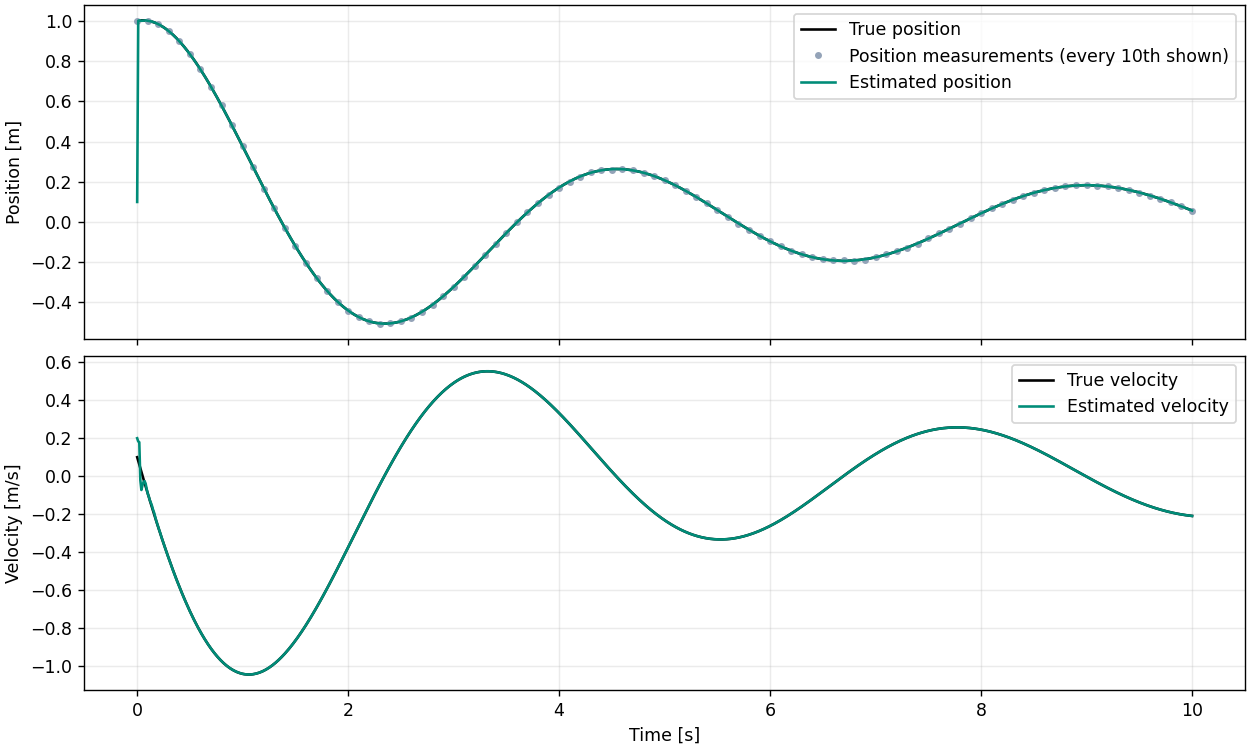

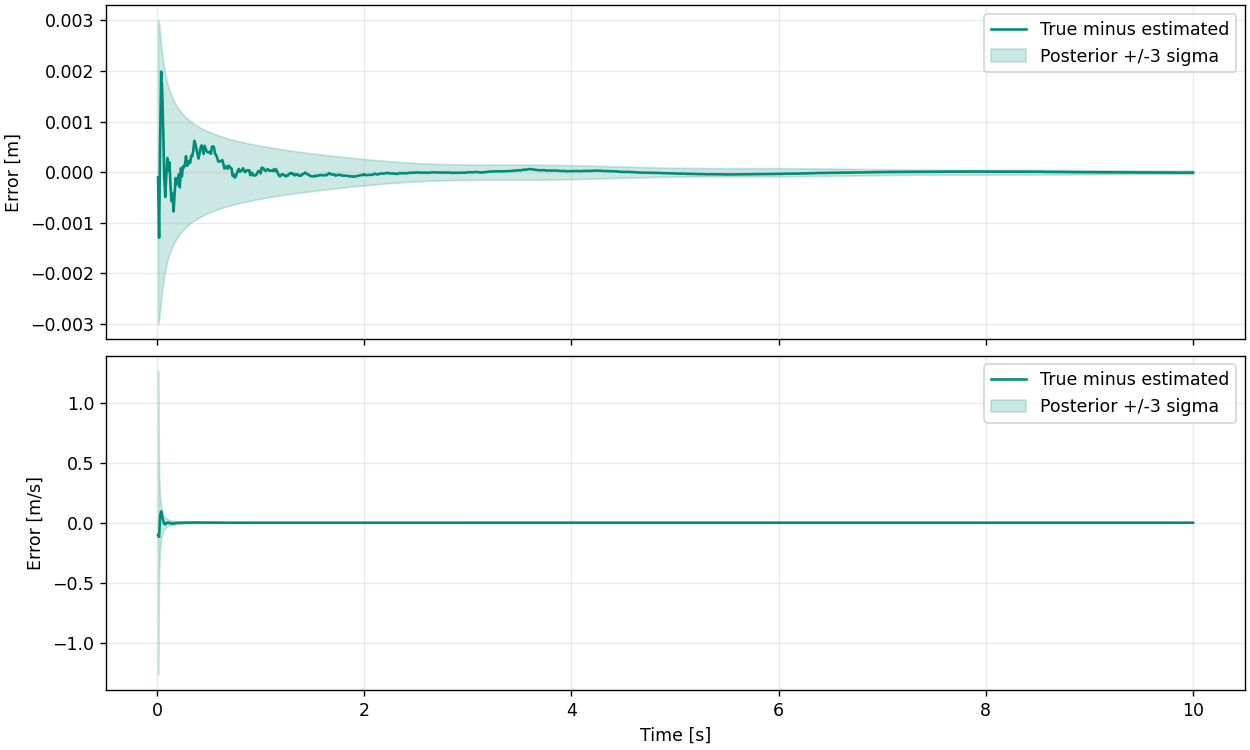

In [7]:
error_state = x - x_hat  # Demo: estimation error relative to truth.
rmse = np.sqrt(np.mean(error_state[:, 1:]**2, axis=1))  # Demo: RMSE after assimilating y_1 onward.
print(f'Position RMSE: {rmse[0]:.6g} m; velocity RMSE: {rmse[1]:.6g} m/s')  # Demo: physical error units.
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, layout='constrained')  # Tutorial: state reconstruction.
axes[0].plot(t, x[0], color='black', label='True position')  # Demo: true measured state.
axes[0].plot(t[::10], y[0, ::10], '.', color='#94a3b8', label='Position measurements (every 10th shown)')  # Demo: readable observation overlay.
axes[0].plot(t, x_hat[0], color='#008c78', label='Estimated position')  # Paper posterior mean, first component.
axes[0].set_ylabel('Position [m]')  # Tutorial: physical position units.
axes[1].plot(t, x[1], color='black', label='True velocity')  # Demo: unmeasured true state.
axes[1].plot(t, x_hat[1], color='#008c78', label='Estimated velocity')  # Paper posterior mean, second component.
axes[1].set(xlabel='Time [s]', ylabel='Velocity [m/s]')  # Tutorial: physical velocity and time units.
for ax in axes:  # Tutorial: common plot formatting.
    ax.grid(alpha=0.25)  # Tutorial: aid reading of time and state values.
    ax.legend(loc='best')  # Tutorial: identify each curve.
plt.show()  # Tutorial: render state trajectories.

sigma = np.sqrt(np.diagonal(P_history, axis1=1, axis2=2)).T  # Paper covariance: marginal standard deviations.
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, layout='constrained')  # Tutorial: error and uncertainty.
for ell, units in enumerate(('m', 'm/s')):  # Demo: position and velocity components.
    axes[ell].plot(t[1:], error_state[ell, 1:], color='#008c78', label='True minus estimated')  # Demo: omit the unassimilated initial prior.
    axes[ell].fill_between(t[1:], -3*sigma[ell, 1:], 3*sigma[ell, 1:], alpha=0.2, color='#008c78', label='Posterior +/-3 sigma')  # Model-based uncertainty envelope.
    axes[ell].set_ylabel(f'Error [{units}]')  # Tutorial: state-error units.
    axes[ell].grid(alpha=0.25)  # Tutorial: readable error trajectories.
    axes[ell].legend(loc='best')  # Tutorial: identify error and envelope.
axes[1].set_xlabel('Time [s]')  # Tutorial: common time axis.
plt.show()  # Tutorial: render error diagnostics.


## Numerical validation against the linear Kalman filter

This MSD model and its observation are affine. Thus the sigma-point moments reproduce the linear moments in exact arithmetic. Here $H\mathbf R^v=0$ also makes the paper's one-set measurement moments agree with the standard linear KF. Use an independent KF as a benchmark:
$$\hat{\mathbf x}_k^-=A_d\hat{\mathbf x}_{k-1}+B_du_{k-1},\quad
\mathbf P_k^-=A_d\mathbf P_{k-1}A_d^T+\mathbf R^v,$$
$$\mathbf P_{\tilde y_k\tilde y_k}=H\mathbf P_k^-H^T+\mathbf R^n,\quad
\mathbf P_{x_ky_k}=\mathbf P_k^-H^T.$$
The benchmark uses the Joseph covariance expression to provide a separate numerical check of the subtractive UKF/factor downdate result. The checks compare the entire state and covariance histories, not only the final states, and check positive definiteness and sigma-point reconstruction.


In [8]:
def run_linear_kf(y, u, x_hat0, P0):  # Independent affine-model reference for numerical validation.
    N = y.shape[1]  # Validation: measurement count.
    means = np.empty((L, N))  # Validation: posterior mean history.
    covariances = np.empty((N, L, L))  # Validation: posterior covariance history.
    means[:, 0], covariances[0] = x_hat0, P0  # Reference: same initial prior.
    for k in range(1, N):  # Reference: one update per y_k.
        mean_minus = Ad @ means[:, k-1] + Bd.ravel() * u[k-1]  # Linear prediction.
        P_minus = Ad @ covariances[k-1] @ Ad.T + Rv  # Full predicted covariance.
        P_yy = H @ P_minus @ H.T + Rn  # Innovation covariance, including all process contributions.
        P_xy = P_minus @ H.T  # Linear cross covariance.
        K = np.linalg.solve(P_yy.T, P_xy.T).T  # Solve for the reference Kalman gain.
        means[:, k] = mean_minus + K @ (y[:, k] - H @ mean_minus)  # Posterior mean.
        J = np.eye(L) - K @ H  # Reference Joseph-form residual map.
        covariances[k] = J @ P_minus @ J.T + K @ Rn @ K.T  # Independent positive-semidefinite covariance expression.
    return means, covariances  # Reference histories.

x_kf, P_kf = run_linear_kf(y, u, x_hat0, P0)  # Execute the independent KF benchmark.
mean_gap = np.max(np.abs(x_hat - x_kf))  # Validation: all-time state disagreement.
cov_gap = np.max(np.abs(P_history - P_kf))  # Validation: all-time covariance disagreement.
min_eigenvalue = np.linalg.eigvalsh(P_history).min()  # Validation: smallest posterior covariance eigenvalue.
X0 = sigma_points(x_hat0, np.linalg.cholesky(P0), eta)  # Eq. (6)/(17): initial sigma set.
D0 = X0 - x_hat0[:, None]  # Initial sigma deviations.
np.testing.assert_allclose(X0 @ Wm, x_hat0, atol=1e-14)  # Validate sigma-point mean reconstruction.
np.testing.assert_allclose((D0 * Wc) @ D0.T, P0, atol=1e-14)  # Validate sigma-point covariance reconstruction.
assert np.allclose(H @ Rv, 0.0)  # Validate the one-set timing condition used for this benchmark.
assert np.all(np.isfinite(x_hat)) and np.all(np.isfinite(P_history))  # Require finite filter results.
assert min_eigenvalue > 0.0  # Every stored posterior must be positive definite here.
np.testing.assert_allclose(x_hat, x_kf, rtol=1e-8, atol=2e-9)  # Require agreement with the independent KF.
np.testing.assert_allclose(P_history, P_kf, rtol=1e-7, atol=2e-11)  # Require covariance agreement.
print(f'Max |state - KF|: {mean_gap:.3e}; max |P - KF|: {cov_gap:.3e}')  # Validation evidence.
print(f'Minimum posterior eigenvalue: {min_eigenvalue:.3e}; all KF checks passed.')  # Validation evidence.


Max |state - KF|: 9.195e-14; max |P - KF|: 2.405e-14
Minimum posterior eigenvalue: 1.208e-10; all KF checks passed.


## Additional factor checks

The affine MSD central deviation is almost zero in exact arithmetic. Therefore a separate nonzero weighted-vector check verifies the signed update/downdate algebra, alongside a complete MSD run with negative $W_0^{(c)}$ and an invalid-downdate rejection check.


In [9]:
C_test = np.array([[1.0, 0.3, 0.1], [0.2, 0.8, -0.1]])  # Validation: a correlated, nonsquare QR input.
S_test = qr_column_factor(C_test)  # Section 3: QR factor construction.
np.testing.assert_allclose(S_test @ S_test.T, C_test @ C_test.T, atol=1e-14)  # Check the QR product.
z_test = np.array([0.2, -0.1])  # Validation: a nonzero rank-one vector.
for weight in (0.7, -0.7, 0.0):  # Validation: positive, negative, and zero contributions.
    S_new = signed_cholupdate(S_test, z_test, weight)  # Eqs. (21)/(25): signed weighted update.
    expected = C_test @ C_test.T + weight * np.outer(z_test, z_test)  # Independent full-covariance target.
    np.testing.assert_allclose(S_new @ S_new.T, expected, atol=1e-14)  # Check the update/downdate product.
assert np.all(np.diagonal(S_history, axis1=1, axis2=2) > 0.0)  # Check positive factor diagonals at every step.
np.testing.assert_allclose(S_history, np.tril(S_history), atol=1e-14)  # Check the stored lower-triangular convention.
eta_negative, Wm_negative, Wc_negative = weights(L, alpha=0.1)  # Section 2: select a negative central covariance weight.
assert Wc_negative[0] < 0.0  # Ensure the negative-weight branch is selected.
x_negative, S_negative, _, _ = run_srukf(y, u, x_hat0, P0, eta_negative, Wm_negative, Wc_negative)  # Exercise Eq. (21)/(25) downdates in the MSD recursion.
np.testing.assert_allclose(x_negative, x_kf, rtol=1e-7, atol=2e-8)  # Affine-model results remain equal within roundoff.
P_negative = S_negative @ S_negative.transpose(0, 2, 1)  # Validation-only factor reconstruction.
np.testing.assert_allclose(P_negative, P_kf, rtol=1e-7, atol=2e-11)  # Check the negative-weight covariance history.
try:  # Validation: an impossible downdate must raise an exception.
    signed_cholupdate(np.eye(2), np.array([2.0, 0.0]), -1.0)  # This would create a negative covariance pivot.
except np.linalg.LinAlgError:  # Expected behavior of a rejected nonpositive downdate.
    print('Invalid downdate correctly rejected.')  # Validation evidence.
else:  # Validation: no exception would indicate a violated numerical contract.
    raise AssertionError('An invalid downdate was accepted.')  # Fail the numerical check.
print('QR, weighted updates/downdates, factor structure, and negative W_0^(c) checks passed.')  # Validation evidence.


Invalid downdate correctly rejected.
QR, weighted updates/downdates, factor structure, and negative W_0^(c) checks passed.


## Interpreting the result and continuing the tutorial

Position is measured; velocity is inferred from the coupling in the state transition. The two-row observability matrix is
$$\mathcal O=\begin{bmatrix}H\\HA_d\end{bmatrix}
=\begin{bmatrix}1&0\\1&T_s\end{bmatrix},$$
with determinant $T_s\ne0$, so both states are observable in this discretized model. The early velocity transient reflects the deliberately different initial mean and the position-only sensor.

The uncertainty bands are $\pm3\sqrt{P_{k,ii}}$ about the estimate under the assumed Gaussian model. They are not deterministic error bounds. The simulated initial truth is fixed, so a single plotted trajectory does not establish statistical consistency. RMSE here excludes the unassimilated initial sample but includes the convergence transient.

Suggested experiments, rerunning from the setup cell:

1. Increase measurement standard deviation `v` by a factor of 10 and observe how the velocity estimate and posterior uncertainty change. `Rn` must change as `v**2`.
2. Change `x_hat0` and `P0` together to compare initial trust with the convergence transient.
3. Change `alpha` using the Section 2 weights. For this affine model, the exact moments do not depend on `alpha`; very small values can increase cancellation in finite precision.
4. Run the companion notebook and compare its RMSE and KF-agreement outputs. Both Python notebooks generate identical inputs and observations from the same random seed. MATLAB's and NumPy's random streams need not be identical across languages.

This linear example demonstrates the algorithm mechanics and factor algebra. It does not establish an accuracy advantage over a linear KF, nonlinear-filter robustness, parameter-estimation behavior, or a runtime speed advantage. State dimension is $L=2$; the state-estimation algorithm is the subject of this tutorial, not the paper's parameter-estimation Algorithm 3.2.


## MATLAB correspondence and how to run

The companion `MSD_SRUKF.m` is self-contained and comments every executable line. Run it in MATLAB R2016b or later. All stored `S` factors follow $P=SS^T$ and are lower triangular.

| Operation | Python | MATLAB | Paper |
|---|---|---|---|
| Initial factor | `np.linalg.cholesky(P0)` | `chol(P0,'lower')` | Eq. (16) |
| QR column factor | `qr(C.T)` then `R_upper.T` | `[~,R_upper]=qr(C.',0)` then `R_upper.'` | Eqs. (20)/(24) |
| Signed rank-one operation | `signed_cholupdate(S,z,weight)` | `cholupdate(S.',sqrt(abs(weight))*z,sign).'` | Eqs. (21)/(25) |
| First gain solve | `solve_triangular(S_y,P_xy.T,lower=True).T` | `P_xy/S_y.'` | Eq. (27) |
| Second gain solve | `solve_triangular(S_y.T,intermediate.T,lower=False).T` | `intermediate/S_y` | Eq. (27) |
| Downdate vector | `K @ S_y` | `K*S_y` | Eq. (28) |
| Posterior factor | lower-factor rank-one downdates | `cholupdate(S_minus.',U(:,ell),'-').'` for each column | Eq. (29) |

The transpose wrappers reflect MATLAB's upper-factor `cholupdate` interface, while the paper defines a column factor. The MATLAB helper requests one output for both `'+'` and `'-'`: `R_upper = cholupdate(S.', scaled_column, operation)`. MATLAB's optional second output is supported for the `'-'` downdate syntax only. With one output, an invalid downdate raises an error automatically. See the [MathWorks cholupdate documentation](https://www.mathworks.com/help/matlab/ref/cholupdate.html). Row sign normalization after QR ensures positive factor diagonals. `P_history` is reconstructed for plots and validation only; the SR recursion carries `S_history` directly.

Both scripts share the same MATLAB data generation. Both Python notebooks share the same NumPy data generation. Random numbers need not match across languages. Install NumPy, SciPy, and Matplotlib; open this notebook in JupyterLab, Jupyter Notebook, or VS Code and use **Run All**. It has no external Python module dependency.


## Source and scope

Rudolph van der Merwe and Eric A. Wan, **The Square-Root Unscented Kalman Filter for State and Parameter-Estimation**, supplied as `srukf.pdf`.

Equation numbers refer to that attached four-page paper: Section 2 and Algorithm 2.1 on page 2; Section 3 and Algorithm 3.1 on page 3. The MSD dynamics, simulation values, Euler discretization, plotting, and validation examples are tutorial constructions. Algorithmic equations are transcribed using the paper's symbols; descriptive code aliases identify hats, superscripts, and subscripts that cannot be Python/MATLAB identifiers. The tutorial explains implementation conventions explicitly where indexing or triangular-factor interfaces need clarification.
